# Лабораторная работа №7. Проективная геометрия и калибровка камеры

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №7».

**Данные.** `data/chessboard/left01…left14.jpg` — 13 реальных кадров шахматной доски 640×480 из примеров OpenCV (кадра `left10` в наборе нет). Доска имеет 9×6 внутренних углов.

> **Что нужно заменить перед сдачей.** Задание требует распечатать доску, измерить клетку и снять 10–15 кадров **своей** камерой. Здесь используется готовый набор, снятый чужой камерой; физический размер клетки для него неизвестен, поэтому расстояния считаются в «клетках». На внутренние параметры камеры ($f_x,f_y,c_x,c_y$, дисторсия) размер клетки не влияет — только на масштаб векторов сдвига.

## 1. О чём эта работа

### Знакомый пример

Камера-обскура: тёмная коробка с маленькой дырочкой. Свет от предмета проходит через дырочку и рисует на задней стенке перевёрнутое изображение. Чем дальше предмет, тем меньше он на стенке. Чем глубже коробка, тем крупнее изображение. Любая камера в первом приближении — такая коробка.

### Основная идея

Нужна формула: «точка в мире с координатами $(X,Y,Z)$ попадёт в пиксель $(u,v)$». Если формула известна, камера становится измерительным прибором: можно по картинке восстанавливать направления и расстояния. Параметры формулы у каждой камеры свои. **Калибровка** — их определение: фотографируем объект с точно известной геометрией (шахматную доску) с разных сторон и подбираем параметры так, чтобы формула как можно точнее объясняла, где на снимках оказались углы клеток.

### Понятия

- **Pinhole model** — модель «коробки с дырочкой». Из подобия треугольников: точка на расстоянии $Z$ со смещением $X$ попадёт на расстояние $f\cdot X/Z$ от центра кадра. Деление на $Z$ — и есть перспектива.
- **Фокусное расстояние в пикселях** $f_x,f_y$ — «глубина коробки», выраженная в размерах пикселя. Двух чисел достаточно, чтобы учесть неквадратные пиксели.
- **Главная точка** $(c_x,c_y)$ — пиксель, в который попадает луч, идущий вдоль оптической оси. Обычно около центра кадра.
- **Матрица внутренних параметров** $K=\begin{bmatrix}f_x&0&c_x\\0&f_y&c_y\\0&0&1\end{bmatrix}$ — свойство самой камеры, не зависит от того, куда она смотрит.
- **Внешние параметры** $R,t$ — поворот и сдвиг, переводящие координаты из системы мира (доски) в систему камеры. У каждого кадра свои.
- **Нормированные координаты** $(x,y)=(X/Z,\,Y/Z)$ — координаты на воображаемой плоскости на расстоянии 1 от дырочки, до умножения на $K$.
- **Дисторсия** — объектив искривляет изображение: прямые линии у краёв кадра выгибаются («бочка» или «подушка»). **Радиальная** дисторсия сдвигает точку вдоль луча от центра тем сильнее, чем дальше она от центра; описывается коэффициентами $k_1,k_2$.
- **Reprojection error** — расстояние в пикселях между найденным на снимке углом клетки и местом, куда его помещает формула с подобранными параметрами.

### Формулы

Полная модель в однородных координатах (см. лабораторную 6):

$$s\,p=K\,[R\,|\,t]\,P$$

$P=(X,Y,Z,1)$ — точка мира, $[R|t]$ — матрица 3×4, $p=(u,v,1)$ — пиксель, $s$ — глубина точки, на которую потом делят.

Когда точка уже в системе камеры:

$$u=f_x\frac{X}{Z}+c_x,\qquad v=f_y\frac{Y}{Z}+c_y$$

Радиальная дисторсия нормированных координат ($r^2=x^2+y^2$):

$$x_d=x\,(1+k_1r^2+k_2r^4),\qquad y_d=y\,(1+k_1r^2+k_2r^4)$$

In [1]:
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

IMAGES = sorted(glob.glob("data/chessboard/left*.jpg"))
PATTERN = (9, 6)          # внутренних углов: по ширине, по высоте
SQUARE = 1.0              # размер клетки; физический размер неизвестен → единица = 1 клетка

## 2. Вопрос 1 — проекция точки

> Для `K=[[800,0,320],[0,820,240],[0,0,1]]` и `P=(0.5,−0.2,2)` найдите пиксельные координаты.

Точка уже задана в системе камеры: на 0.5 м правее оси, на 0.2 м выше (в системе камеры ось $y$ направлена вниз, поэтому «выше» — отрицательное $Y$), на расстоянии 2 м.

**Шаг 1. Нормированные координаты:** $x=X/Z=0.5/2=0.25$, $y=Y/Z=-0.2/2=-0.1$.

**Шаг 2. Умножение на фокусное и сдвиг к главной точке:**

$$u=800\cdot0.25+320=200+320=520,\qquad v=820\cdot(-0.1)+240=-82+240=158$$

**Смысл.** Точка правее и выше центра кадра $(320, 240)$ — и пиксель получился правее ($520>320$) и выше ($158<240$). Если отодвинуть точку вдвое дальше ($Z=4$), смещения от центра уменьшатся вдвое: $(420, 199)$.

**То же через матрицы.** $K\cdot P=(800\cdot0.5+320\cdot2,\ 820\cdot(-0.2)+240\cdot2,\ 2)=(1040,\,316,\,2)$; делим на третью координату: $(520,158)$.

In [2]:
K1 = np.array([[800.0, 0, 320], [0, 820, 240], [0, 0, 1]])
P = np.array([0.5, -0.2, 2.0])
x, y = P[0] / P[2], P[1] / P[2]
print("нормированные координаты:", (x, y))
print("u =", K1[0, 0] * x + K1[0, 2], " v =", K1[1, 1] * y + K1[1, 2])
hom = K1 @ P
print("K·P =", hom, " → после деления на s =", hom[2], ":", hom[:2] / hom[2])
print("та же точка на Z=4:", (K1 @ np.array([0.5, -0.2, 4.0]))[:2] / 4)

нормированные координаты: (np.float64(0.25), np.float64(-0.1))
u = 520.0  v = 158.0
K·P = [1040.  316.    2.]  → после деления на s = 2.0 : [520. 158.]
та же точка на Z=4: [420. 199.]


**Итог вопроса 1:** $(u,v)=(520,158)$.

## 3. Вопрос 2 — дисторсия и оценка фокусного расстояния

> Для normalized point (0.4,0.3), k1=−0.2, k2=0.05 найдите distorted coordinates. Затем оцените f_x least squares по (X/Z,u): (.1,400),(.2,482),(.3,558), c_x=320.

### Дисторсия

**Шаг 1.** $r^2=0.4^2+0.3^2=0.16+0.09=0.25$ (точка на расстоянии $r=0.5$ от центра), $r^4=0.0625$.

**Шаг 2. Множитель:** $1+k_1r^2+k_2r^4=1-0.2\cdot0.25+0.05\cdot0.0625=1-0.05+0.003125=0.953125$.

**Шаг 3.** $x_d=0.4\cdot0.953125=0.38125$, $y_d=0.3\cdot0.953125\approx0.28594$.

**Смысл.** Множитель меньше единицы — точка сдвинулась к центру на ≈4.7 %. Отрицательный $k_1$ — это «бочка»: края кадра стягиваются к центру, прямые выгибаются наружу. Слагаемое с $k_2$ — поправка, заметная только далеко от центра. Направление от центра не изменилось: $y_d/x_d=0.75$, как и было.

### Оценка $f_x$ методом наименьших квадратов

Модель: $u=f_x\cdot(X/Z)+c_x$. Переносим известное $c_x$: $u-c_x=f_x\cdot a$, где $a=X/Z$.

| $a=X/Z$ | $u$ | $b=u-320$ | $b/a$ |
|---|---|---|---|
| 0.1 | 400 | 80 | 800 |
| 0.2 | 482 | 162 | 810 |
| 0.3 | 558 | 238 | 793.3 |

Три измерения дают три разных значения $f_x$ — данные с шумом, неизвестное одно. Точного решения нет, ищем $f$, минимизирующий сумму квадратов невязок:

$$E(f)=\sum_i(a_if-b_i)^2$$

Производная по $f$ равна нулю: $\sum_i 2a_i(a_if-b_i)=0$, откуда

$$f=\frac{\sum a_ib_i}{\sum a_i^2}=\frac{a^Tb}{a^Ta}$$

- $a^Tb=0.1\cdot80+0.2\cdot162+0.3\cdot238=8+32.4+71.4=111.8$
- $a^Ta=0.01+0.04+0.09=0.14$
- $f_x=111.8/0.14\approx798.57$ px

**Смысл.** Это не простое среднее трёх отношений ($801.1$): измерения с большим $a$ получают больший вес. Так и должно быть — ошибка в один пиксель при $a=0.3$ меняет оценку $f$ втрое меньше, чем при $a=0.1$, то есть дальние от центра точки информативнее.

In [3]:
xn, yn, k1, k2 = 0.4, 0.3, -0.2, 0.05
r2 = xn ** 2 + yn ** 2
factor = 1 + k1 * r2 + k2 * r2 ** 2
print(f"r² = {r2}, r⁴ = {r2 ** 2}, множитель = {factor}")
print(f"x_d = {xn * factor:.5f}, y_d = {yn * factor:.5f}")

a = np.array([0.1, 0.2, 0.3]); u = np.array([400.0, 482.0, 558.0]); cx = 320.0
b = u - cx
f_ls = (a @ b) / (a @ a)
print("\nb = u − c_x:", b, " b/a:", b / a)
print(f"aᵀb = {a @ b}, aᵀa = {a @ a:.2f}, f_x = {f_ls:.3f} px")
print("np.linalg.lstsq:", np.linalg.lstsq(a[:, None], b, rcond=None)[0][0])
print("невязки, px:", a * f_ls - b, " простое среднее b/a:", (b / a).mean())

r² = 0.25, r⁴ = 0.0625, множитель = 0.953125
x_d = 0.38125, y_d = 0.28594

b = u − c_x: [ 80. 162. 238.]  b/a: [800.     810.     793.3333]
aᵀb = 111.8, aᵀa = 0.14, f_x = 798.571 px
np.linalg.lstsq: 798.5714285714284
невязки, px: [-0.1429 -2.2857  1.5714]  простое среднее b/a: 801.1111111111112


**Итог вопроса 2:** $(x_d,y_d)\approx(0.3813,\ 0.2859)$; $f_x\approx798.6$ px.

## 4. Задание 3 — код и эксперимент

### Шаги 1–4. Доска, кадры, поиск углов, objectPoints

`findChessboardCorners` находит внутренние углы клеток; `cornerSubPix` уточняет их положение до долей пикселя. `objectPoints` — координаты тех же углов на самой доске: доска плоская, поэтому $Z=0$, а $X,Y$ — номер угла, умноженный на размер клетки. Для всех кадров они одинаковы.

кадров с найденной доской: 13 из 13, размер (640, 480), углов на кадр: 54


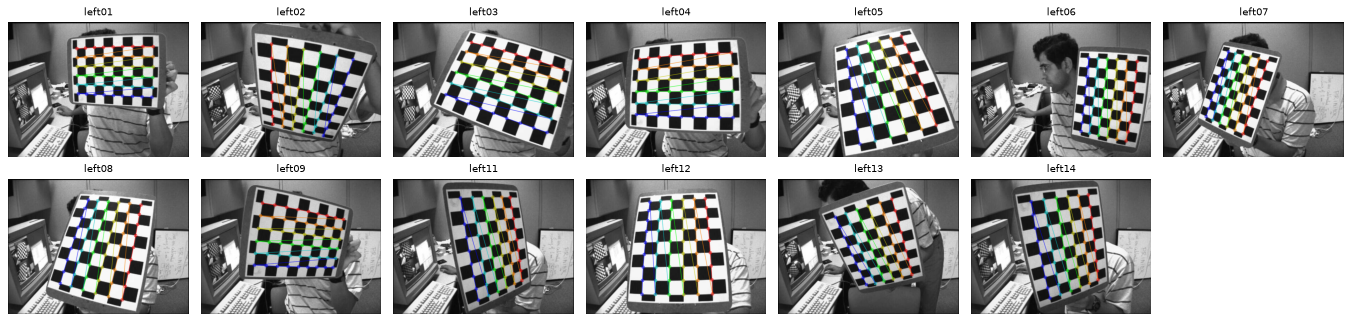

In [4]:
objp = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:PATTERN[0], 0:PATTERN[1]].T.reshape(-1, 2) * SQUARE

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
objpoints, imgpoints, names, grays = [], [], [], []
for path in IMAGES:
    g = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    found, corners = cv2.findChessboardCorners(g, PATTERN)
    if not found:
        print("углы не найдены:", path)
        continue
    corners = cv2.cornerSubPix(g, corners, (11, 11), (-1, -1), criteria)
    objpoints.append(objp); imgpoints.append(corners); names.append(path[-10:-4]); grays.append(g)

image_size = grays[0].shape[::-1]
print(f"кадров с найденной доской: {len(names)} из {len(IMAGES)}, размер {image_size}, углов на кадр: {len(objp)}")

fig, ax = plt.subplots(2, 7, figsize=(17, 4.2))
for a_, g, c, n in zip(ax.ravel(), grays, imgpoints, names):
    a_.imshow(cv2.drawChessboardCorners(cv2.cvtColor(g, cv2.COLOR_GRAY2BGR), PATTERN, c, True)[..., ::-1]); a_.set_title(n, fontsize=9)
for a_ in ax.ravel(): a_.axis("off")
plt.tight_layout(); plt.show()

### Шаг 5. Калибровка

`calibrateCamera` подбирает $K$, коэффициенты дисторсии и по паре $(R,t)$ на каждый кадр, минимизируя сумму квадратов ошибок репроекции по всем углам всех кадров. OpenCV возвращает пять коэффициентов дисторсии в порядке $(k_1,k_2,p_1,p_2,k_3)$: $k$ — радиальные, $p$ — тангенциальные (от неидеальной параллельности линзы и матрицы).

In [5]:
def calibrate(objp_list, imgp_list):
    rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(objp_list, imgp_list, image_size, None, None)
    return rms, K, dist.ravel(), rvecs, tvecs

rms, K, dist, rvecs, tvecs = calibrate(objpoints, imgpoints)
print("RMS, который вернул OpenCV:", round(rms, 4), "px")
print("K =\n", K)
print("dist (k1, k2, p1, p2, k3) =", dist)
print("центр кадра:", (image_size[0] / 2, image_size[1] / 2), " главная точка:", (round(K[0, 2], 1), round(K[1, 2], 1)))

RMS, который вернул OpenCV: 0.4085 px
K =
 [[536.0824   0.     342.3705]
 [  0.     536.0267 235.5449]
 [  0.       0.       1.    ]]
dist (k1, k2, p1, p2, k3) = [-0.2651 -0.0461  0.0018 -0.0003  0.2505]
центр кадра: (320.0, 240.0)  главная точка: (np.float64(342.4), np.float64(235.5))


### Шаги 6–7. Репроекция и собственный RMSE по кадрам

Сначала — собственная реализация проекции по формулам раздела 1, чтобы убедиться, что `cv2.projectPoints` делает именно это: поворот и сдвиг → деление на $Z$ → дисторсия → умножение на $K$.

Вектор поворота `rvec` — компактная запись поворота тремя числами (направление — ось вращения, длина — угол); `cv2.Rodrigues` превращает его в матрицу $R$ 3×3.

In [6]:
def project_manual(obj, rvec, tvec, K, dist):
    R, _ = cv2.Rodrigues(rvec)
    Pc = obj @ R.T + tvec.reshape(1, 3)                 # в систему камеры
    x, y = Pc[:, 0] / Pc[:, 2], Pc[:, 1] / Pc[:, 2]     # перспективное деление
    k1, k2, p1, p2, k3 = dist
    r2 = x * x + y * y
    radial = 1 + k1 * r2 + k2 * r2 ** 2 + k3 * r2 ** 3
    xd = x * radial + 2 * p1 * x * y + p2 * (r2 + 2 * x * x)
    yd = y * radial + p1 * (r2 + 2 * y * y) + 2 * p2 * x * y
    return np.column_stack([K[0, 0] * xd + K[0, 2], K[1, 1] * yd + K[1, 2]])

proj_cv, _ = cv2.projectPoints(objp, rvecs[0], tvecs[0], K, dist)
print("max |своя проекция − cv2.projectPoints| =", np.abs(project_manual(objp.astype(np.float64), rvecs[0], tvecs[0], K, dist) - proj_cv.reshape(-1, 2)).max(), "px")

def per_frame_rmse(objp_list, imgp_list, rvecs, tvecs, K, dist):
    errs = []
    for obj, img_pts, rv, tv in zip(objp_list, imgp_list, rvecs, tvecs):
        proj, _ = cv2.projectPoints(obj, rv, tv, K, dist)
        e = img_pts.reshape(-1, 2) - proj.reshape(-1, 2)           # вектор ошибки для каждого угла
        errs.append(np.sqrt(np.mean(np.sum(e ** 2, axis=1))))      # корень из среднего квадрата расстояния
    return np.array(errs)

errs = per_frame_rmse(objpoints, imgpoints, rvecs, tvecs, K, dist)
for n, e in zip(names, errs):
    print(f"{n}: RMSE = {e:.4f} px")
print("mean reprojection RMSE:", round(errs.mean(), 4), "px")
print("общий RMSE по всем точкам:", round(np.sqrt(np.mean(errs ** 2)), 4), "px — совпадает с RMS из OpenCV:", bool(np.isclose(np.sqrt(np.mean(errs ** 2)), rms, atol=1e-4)))

max |своя проекция − cv2.projectPoints| = 1.8895857238021563e-05 px
left01: RMSE = 0.1935 px
left02: RMSE = 1.2190 px
left03: RMSE = 0.1755 px
left04: RMSE = 0.1938 px
left05: RMSE = 0.1600 px
left06: RMSE = 0.1827 px
left07: RMSE = 0.2382 px
left08: RMSE = 0.2431 px
left09: RMSE = 0.3009 px
left11: RMSE = 0.1679 px
left12: RMSE = 0.2022 px
left13: RMSE = 0.4609 px
left14: RMSE = 0.1752 px
mean reprojection RMSE: 0.301 px
общий RMSE по всем точкам: 0.4085 px — совпадает с RMS из OpenCV: True


### Шаг 8. RMSE по кадрам

Заодно для каждого кадра считаем расстояние до доски (длина $t$, в клетках) и угол наклона доски к оптической оси — чтобы понять, чем худший кадр отличается от остальных.

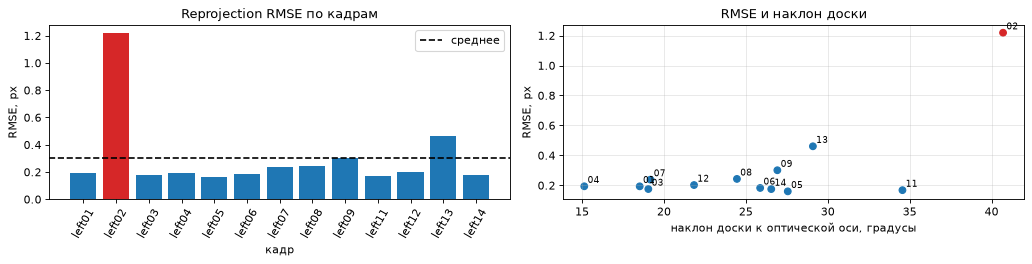

худший кадр: left02, RMSE = 1.2190 px, наклон = 40.7°, расстояние = 14.7 клеток
диапазон наклонов по набору: 15.1°…40.7°, расстояний: 11.9…16.8 клеток


In [7]:
dist_to_board = np.array([np.linalg.norm(t) for t in tvecs])
tilt = np.array([np.degrees(np.arccos(abs(cv2.Rodrigues(r)[0][2, 2]))) for r in rvecs])
worst = int(np.argmax(errs))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
colors = ["tab:red" if i == worst else "tab:blue" for i in range(len(errs))]
ax[0].bar(names, errs, color=colors); ax[0].axhline(errs.mean(), color="k", ls="--", label="среднее")
ax[0].set(title="Reprojection RMSE по кадрам", xlabel="кадр", ylabel="RMSE, px"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend()
ax[1].scatter(tilt, errs, c=colors)
for n, tl, e in zip(names, tilt, errs): ax[1].annotate(n[-2:], (tl, e), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[1].set(title="RMSE и наклон доски", xlabel="наклон доски к оптической оси, градусы", ylabel="RMSE, px"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"худший кадр: {names[worst]}, RMSE = {errs[worst]:.4f} px, наклон = {tilt[worst]:.1f}°, расстояние = {dist_to_board[worst]:.1f} клеток")
print(f"диапазон наклонов по набору: {tilt.min():.1f}°…{tilt.max():.1f}°, расстояний: {dist_to_board.min():.1f}…{dist_to_board.max():.1f} клеток")

### Шаги 9–10. Удаление худшего кадра и повторная калибровка

In [8]:
keep = [i for i in range(len(names)) if i != worst]
rms2, K2, dist2, rvecs2, tvecs2 = calibrate([objpoints[i] for i in keep], [imgpoints[i] for i in keep])
errs2 = per_frame_rmse([objpoints[i] for i in keep], [imgpoints[i] for i in keep], rvecs2, tvecs2, K2, dist2)

print(f"{'Набор':28}{'fx':>9}{'fy':>9}{'cx':>9}{'cy':>9}{'k1':>9}{'Mean RMSE, px':>15}")
print(f"{f'все {len(names)} кадров':28}{K[0,0]:9.2f}{K[1,1]:9.2f}{K[0,2]:9.2f}{K[1,2]:9.2f}{dist[0]:9.4f}{errs.mean():15.4f}")
print(f"{f'без {names[worst]} ({len(keep)} кадров)':28}{K2[0,0]:9.2f}{K2[1,1]:9.2f}{K2[0,2]:9.2f}{K2[1,2]:9.2f}{dist2[0]:9.4f}{errs2.mean():15.4f}")
print(f"{'изменение':28}{K2[0,0]-K[0,0]:9.2f}{K2[1,1]-K[1,1]:9.2f}{K2[0,2]-K[0,2]:9.2f}{K2[1,2]-K[1,2]:9.2f}{dist2[0]-dist[0]:9.4f}{errs2.mean()-errs.mean():15.4f}")
print(f"относительное изменение fx: {100 * (K2[0,0] - K[0,0]) / K[0,0]:.2f} %")

Набор                              fx       fy       cx       cy       k1  Mean RMSE, px
все 13 кадров                  536.08   536.03   342.37   235.54  -0.2651         0.3010
без left02 (12 кадров)         534.14   534.20   342.84   233.73  -0.2760         0.2174
изменение                       -1.94    -1.83     0.47    -1.82  -0.0108        -0.0836
относительное изменение fx: -0.36 %


### Шаг 11. Undistorted image

`cv2.undistort` пересчитывает картинку так, как её сняла бы идеальная камера без дисторсии: прямые линии сцены снова становятся прямыми. Красная линия проведена через крайние углы одного ряда клеток: на исходном кадре углы ряда отклоняются от неё, на исправленном — лежат на ней.

кадр left09: макс. отклонение углов ряда от прямой — до исправления 2.79 px, после 0.25 px
по рядам до   : [2.7878 1.9436 0.8789 0.1761 0.8569 1.5117]
по рядам после: [0.1315 0.1531 0.1264 0.113  0.2306 0.2486]


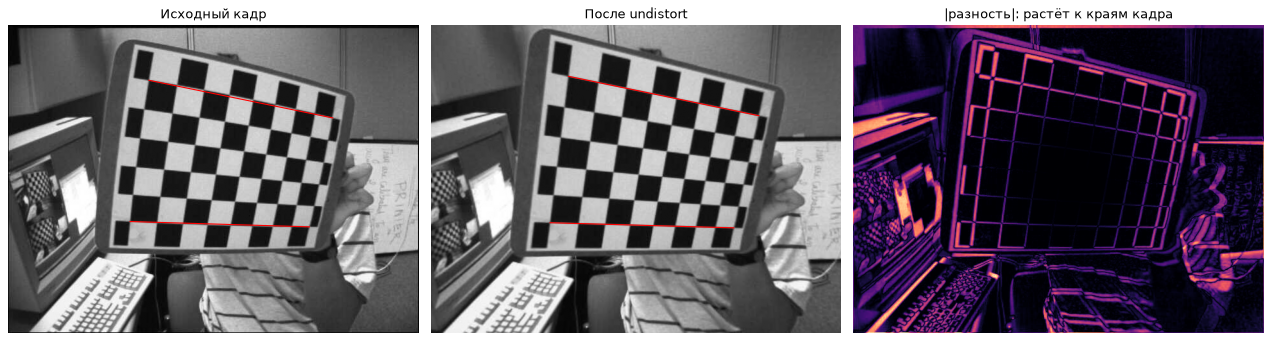

In [9]:
k = int(np.argmin(dist_to_board))                 # самый крупный план: дисторсия заметнее всего
img = grays[k]
und = cv2.undistort(img, K, dist)

def row_straightness(gray_img):
    found, c = cv2.findChessboardCorners(gray_img, PATTERN)
    c = cv2.cornerSubPix(gray_img, c, (11, 11), (-1, -1), criteria).reshape(PATTERN[1], PATTERN[0], 2)
    dev = []
    for row in c:                                     # отклонение углов ряда от прямой через его концы
        d = row[-1] - row[0]; n = np.array([-d[1], d[0]]) / np.linalg.norm(d)
        dev.append(np.abs((row - row[0]) @ n).max())
    return c, np.array(dev)

c0, dev0 = row_straightness(img)
c1, dev1 = row_straightness(und)
print(f"кадр {names[k]}: макс. отклонение углов ряда от прямой — до исправления {dev0.max():.2f} px, после {dev1.max():.2f} px")
print("по рядам до   :", dev0)
print("по рядам после:", dev1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a_, (im, c, title) in zip(ax, [(img, c0, "Исходный кадр"), (und, c1, "После undistort")]):
    a_.imshow(im); a_.plot(c[0, [0, -1], 0], c[0, [0, -1], 1], "r-", lw=1); a_.plot(c[-1, [0, -1], 0], c[-1, [0, -1], 1], "r-", lw=1)
    a_.set_title(title); a_.axis("off")
ax[2].imshow(cv2.absdiff(img, und), cmap="magma"); ax[2].set_title("|разность|: растёт к краям кадра"); ax[2].axis("off")
plt.tight_layout(); plt.show()

## 5. Неудачный случай: мало кадров и все похожи

Калибруем по двум и трём кадрам с почти одинаковым наклоном доски и сравниваем с тремя кадрами разного наклона. Выброс `left02` исключён из всех наборов. Столбец `test` — ошибка на кадрах, **не участвовавших** в калибровке: для них подбирается только поза доски (`solvePnP`), а $K$ и дисторсия берутся готовые.

In [10]:
pool = keep                                # без выброса left02, чтобы он не искажал сравнение
order = [i for i in np.argsort(tilt) if i in pool]
similar3 = order[:3]                                       # три кадра с наименьшим наклоном
similar2 = order[:2]
diverse3 = [order[0], order[len(order) // 2], order[-1]]   # малый, средний и большой наклон

def subset_report(label, idx):
    r, Ks, ds, rv, tv = calibrate([objpoints[i] for i in idx], [imgpoints[i] for i in idx])
    # проверка на кадрах, не участвовавших в калибровке: позу подбираем, K и dist фиксированы
    e_test = []
    for i in [i for i in pool if i not in idx]:
        ok, rvi, tvi = cv2.solvePnP(objpoints[i], imgpoints[i], Ks, ds)
        pr, _ = cv2.projectPoints(objpoints[i], rvi, tvi, Ks, ds)
        e_test.append(np.sqrt(np.mean(np.sum((imgpoints[i].reshape(-1, 2) - pr.reshape(-1, 2)) ** 2, axis=1))))
    tl = ", ".join(f"{tilt[i]:.0f}°" for i in idx) if len(idx) <= 3 else f"{tilt[idx].min():.0f}°…{tilt[idx].max():.0f}°"
    test = f"{np.mean(e_test):.3f}" if e_test else "—"
    print(f"{label:18}{tl:>14}{Ks[0,0]:9.1f}{Ks[1,1]:9.1f}{Ks[0,2]:8.1f}{Ks[1,2]:8.1f}{ds[0]:8.3f}{r:11.3f}{test:>9}")

print(f"{'набор':18}{'наклоны':>14}{'fx':>9}{'fy':>9}{'cx':>8}{'cy':>8}{'k1':>8}{'RMS train':>11}{'test':>9}")
subset_report("2 похожих кадра", similar2)
subset_report("3 похожих кадра", similar3)
subset_report("3 разных кадра", diverse3)
subset_report(f"все {len(pool)} кадров", np.array(pool))

набор                    наклоны       fx       fy      cx      cy      k1  RMS train     test
2 похожих кадра         15°, 19°    515.3    514.1   344.5   233.3  -0.255      0.171    0.429
3 похожих кадра    15°, 19°, 19°    537.9    538.1   334.1   233.9  -0.303      0.160    0.277
3 разных кадра     15°, 26°, 35°    528.0    528.7   339.6   233.5  -0.271      0.161    0.258
все 12 кадров            15°…35°    534.1    534.2   342.8   233.7  -0.276      0.234        —


Ошибка на «своих» кадрах у всех малых наборов низкая (0.16–0.17 px) — ниже, чем у калибровки по 12 кадрам (0.23 px). Но это не значит, что параметры лучше:

- **два похожих кадра:** $f_x=515$ px против 534 px у полного набора — ошибка 3.5 %, и на новых кадрах ошибка 0.43 px, в 2.5 раза больше, чем на своих;
- **три похожих кадра:** фокусное почти верное, но главная точка сдвинута на ≈9 px по $x$, $k_1$ отличается на 10 %; на новых кадрах 0.28 px;
- **три разных кадра:** при том же числе кадров ошибка на новых кадрах ниже — 0.26 px, главная точка ближе к полной калибровке.

Малый RMSE на обучающих кадрах не доказывает, что параметры верны: модель с девятью внутренними параметрами и шестью параметрами позы на кадр легко подгоняется под несколько похожих снимков.

Причина — неоднозначность. Когда доска видна под одним и тем же углом, «большое фокусное + доска далеко» и «малое фокусное + доска близко» дают почти одинаковые картинки, и данные не позволяют выбрать между ними. Разные наклоны разрушают неоднозначность: перспективное сокращение (дальний край доски выглядит меньше ближнего) зависит от $f$ и расстояния по-разному.

Оговорка: в этом наборе нет по-настоящему фронтальных кадров (минимальный наклон 15°), поэтому эффект умеренный. На строго фронтальных кадрах оценка фокусного расстояния была бы ещё менее надёжной.

## 6. Вывод

Цифры относятся к набору `left01…left14` из OpenCV, а не к собственной камере.

- **Ручные расчёты** подтверждены кодом: $(u,v)=(520,158)$; $(x_d,y_d)\approx(0.3813,0.2859)$; $f_x\approx798.57$ px.
- **Калибровка** по 13 кадрам: $f_x=536.08$, $f_y=536.03$ px (пиксели практически квадратные), главная точка (342.4, 235.5) при центре кадра (320, 240). Общий RMS 0.4085 px; собственный расчёт по кадрам даёт то же число. Собственная функция проекции совпадает с `cv2.projectPoints` до 2e-5 px.
- **Ошибка по кадрам** неравномерна: у 11 кадров из 13 RMSE 0.16–0.30 px, у `left13` — 0.46 px, у `left02` — 1.22 px. `left02` — кадр с самым большим наклоном доски (40.7° при 15–35° у остальных): при сильном наклоне дальние клетки сжаты, и углы на них локализуются хуже.
- **После удаления `left02`** средний RMSE по кадрам снизился с 0.301 до 0.217 px, а параметры изменились мало: $f_x$ на −0.36 % (−1.9 px), главная точка меньше чем на 2 px. Это признак устойчивой калибровки: один кадр не определяет результат. Если бы параметры сильно «поехали», кадр был бы не выбросом, а источником уникальной информации.
- **Дисторсия** у этой камеры бочкообразная ($k_1\approx-0.27$). На самом крупном кадре (`left09`) углы ряда клеток отклонялись от прямой до 2.79 px; после `undistort` — не более 0.25 px.
- **Ограничение:** калибровка по двум похожим кадрам даёт малую ошибку на них самих (0.17 px), но фокусное с ошибкой 3.5 % и ошибку 0.43 px на остальных кадрах (раздел 5).
- По условию нужны собственные снимки своей камерой; здесь использован готовый набор, размер клетки неизвестен.

## 7. Вопросы на защиту

**1. Что означают fx, fy, cx, cy и почему focal length выражается в пикселях?**
$f_x,f_y$ — фокусное расстояние, делённое на размер пикселя по горизонтали и вертикали: $f_x=f_{мм}/(\text{ширина пикселя в мм})$. $(c_x,c_y)$ — пиксель, куда попадает оптическая ось. В пикселях — потому что формула $u=f_xX/Z+c_x$ должна давать результат в пикселях, а $X/Z$ безразмерно. Физические миллиметры и размер пикселя по отдельности из снимков определить нельзя — только их отношение. Практический смысл $f_x$: объект шириной 1 м на расстоянии 1 м займёт $f_x$ пикселей.

**2. Почему набор почти одинаковых фронтальных кадров даёт слабую калибровку?**
Число кадров не заменяет разнообразия. Одинаковые кадры дают почти одинаковые уравнения — новой информации нет. При фронтальной доске фокусное расстояние и дистанция до доски компенсируют друг друга: изображение зависит почти только от их отношения. Чтобы их разделить, нужна перспектива внутри кадра — наклон доски. А чтобы оценить дисторсию, нужны углы у краёв кадра, где она велика; в центре её почти нет. См. раздел 5.

**3. Расчёт reprojection RMSE и единицы измерения.**
В `per_frame_rmse`: `cv2.projectPoints` считает, куда модель помещает углы доски; `e = img_pts − proj` — вектор ошибки (2 числа) для каждого из 54 углов; `np.sum(e**2, axis=1)` — квадрат расстояния для каждого угла; `np.mean` — средний по кадру; `np.sqrt` — корень. Единицы — **пиксели изображения**: это расстояние на снимке, а не в пространстве. Значение 0.4 px означает, что модель в среднем ошибается меньше чем на полпикселя.